# 08.07 — Brick 7: Success Dimensions

This notebook is **only Brick 7**.

It does not rebuild the network.  
It does not relabel communities.  
It does not interpret centrality or bridging again.  
It does not run the final association models. That comes in Brick 8.

Its job is to answer one reader question:

> What does “success” mean in this thesis, and why is it not only box-office revenue?

## Thesis-level idea

This thesis treats film success as **multidimensional**.

A film can be successful through:

```text
commercial performance
audience attention
evaluative reception
recognition / awards
```

But the dataset does not measure all dimensions equally.

So this brick explains:

```text
success concept
→ available variables
→ data limitations
→ outcome distributions
→ candidates for non-box-office success
```

## Figures produced

```text
outputs/thesis_bricks/07_success_dimensions/figures/
```

1. `01_success_dimensions_framework.png`  
2. `02_success_variables_measurement_table.png`  
3. `03_outcome_availability_cards.png`  
4. `04_revenue_distribution.png`  
5. `05_vote_average_distribution.png`  
6. `06_attention_distribution.png`  
7. `07_success_quadrant_concept.png`  
8. `08_hidden_evaluative_success_candidates.png`  
9. `09_attention_success_candidates.png`  
10. `10_success_dimensions_summary.png`  

## Design rule

Do not force all success variables into one dense scatterplot.

Show the meaning of each success dimension first, then show selected candidate films clearly.


## 0. Setup

In [1]:

import os, re, math, textwrap, warnings
from pathlib import Path
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import patches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import matplotlib.patheffects as pe

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 220)
pd.set_option("display.max_colwidth", 240)

COL = {
    "ink": "#222222",
    "muted": "#62666D",
    "grid": "#E4E7EB",
    "panel": "#F7F8FA",
    "blue": "#2F6FB3",
    "orange": "#D06C45",
    "green": "#2F8F5B",
    "purple": "#7A5BC2",
    "red": "#C94C4C",
    "yellow": "#D9A21B",
    "light_blue": "#E8F1FB",
    "light_orange": "#FBEADF",
    "light_green": "#E6F4EC",
    "light_purple": "#EFEAFB",
    "light_gray": "#F2F4F7",
    "white": "#FFFFFF",
}

COMM_COLORS = [
    "#4E79A7", "#F28E2B", "#59A14F", "#E15759", "#76B7B2", "#9C755F",
    "#EDC948", "#B07AA1", "#FF9DA7", "#BAB0AC", "#2F6FB3", "#D06C45",
    "#2F8F5B", "#7A5BC2", "#C94C4C", "#D9A21B", "#5C6BC0", "#26A69A",
    "#AB47BC", "#8D6E63", "#78909C", "#EC407A", "#43A047", "#FB8C00",
    "#6D4C41", "#00ACC1"
]

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": COL["ink"],
    "axes.labelcolor": COL["ink"],
    "xtick.color": COL["ink"],
    "ytick.color": COL["ink"],
    "text.color": COL["ink"],
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.titlesize": 18,
    "axes.titleweight": "bold",
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "savefig.dpi": 320,
    "figure.dpi": 130,
})

def save_fig(fig, name, dpi=320):
    png = FIG_DIR / name
    svg = FIG_DIR / name.replace(".png", ".svg")
    fig.savefig(png, dpi=dpi, bbox_inches="tight", facecolor="white")
    fig.savefig(svg, bbox_inches="tight", facecolor="white")
    print("Saved:", png)
    print("Saved:", svg)

def save_table(df, name):
    path = TABLE_DIR / name
    df.to_csv(path, index=False, encoding="utf-8")
    print("Saved:", path)
    return path

def write_text(txt, name):
    path = TEXT_DIR / name
    path.write_text(txt, encoding="utf-8")
    print("Saved:", path)
    return path

def wrap_text(s, width=42):
    if pd.isna(s):
        return ""
    return "\n".join(textwrap.wrap(str(s), width=width))

def shorten(s, width=90):
    if pd.isna(s):
        return ""
    return textwrap.shorten(str(s).replace("\n", " "), width=width, placeholder="...")

def clean_title(x):
    if pd.isna(x):
        return ""
    return str(x).replace("\n", " ").strip()

def title_block(fig, title, subtitle=None, x=0.05, y=0.965):
    fig.text(x, y, title, ha="left", va="top", fontsize=22, fontweight="bold", color=COL["ink"])
    if subtitle:
        fig.text(x, y - 0.055, subtitle, ha="left", va="top", fontsize=12.5, color=COL["muted"])

def community_color(cid):
    try:
        return COMM_COLORS[int(cid) % len(COMM_COLORS)]
    except Exception:
        return COL["blue"]

def safe_read(path):
    path = Path(path)
    if path.exists():
        return pd.read_csv(path)
    print("Missing:", path)
    return None

def fmt_int(x):
    try:
        return f"{int(round(float(x))):,}"
    except Exception:
        return "—"

def fmt_float(x, d=2):
    try:
        return f"{float(x):.{d}f}"
    except Exception:
        return "—"

def first_existing_col(df, candidates):
    for c in candidates:
        if c in df.columns:
            return c
    return None

def scaled_0_10(x):
    """Scale a 0-1 percentile to 0-10 so it can be compared visually with vote_average."""
    return x * 10


## 1. Project paths

In [2]:

try:
    from google.colab import drive
    if Path("/content/drive/MyDrive").exists():
        print("Google Drive already mounted.")
    else:
        drive.mount("/content/drive")
except Exception as e:
    print("Drive mount skipped or failed:", e)

PROJECT_DIR = Path("/content/drive/MyDrive/thesis_movie_project").resolve()

PROCESSED_CORE_DIR = PROJECT_DIR / "processed" / "core"
PROCESSED_NETWORK_DIR = PROJECT_DIR / "processed" / "network"
PROCESSED_FEATURES_DIR = PROJECT_DIR / "processed" / "features"
OUTPUT_TABLES_DIR = PROJECT_DIR / "outputs" / "tables"

FINAL_DIR = PROJECT_DIR / "outputs" / "thesis_bricks" / "07_success_dimensions"
FIG_DIR = FINAL_DIR / "figures"
TABLE_DIR = FINAL_DIR / "tables"
TEXT_DIR = FINAL_DIR / "text"

for d in [FINAL_DIR, FIG_DIR, TABLE_DIR, TEXT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("PROJECT_DIR:", PROJECT_DIR)
print("FINAL_DIR:", FINAL_DIR)


Mounted at /content/drive
PROJECT_DIR: /content/drive/MyDrive/thesis_movie_project
FINAL_DIR: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/07_success_dimensions


## 2. Load files

In [3]:

FILES = {
    "modeling": PROCESSED_FEATURES_DIR / "modeling_table_success_star_power.csv",
    "nodes": PROCESSED_NETWORK_DIR / "semantic_network_nodes_lcc.csv",
    "df_revenue": PROCESSED_CORE_DIR / "df_revenue_analysis.csv",
    "df_roi": PROCESSED_CORE_DIR / "df_roi_analysis.csv",
    "community_labels": OUTPUT_TABLES_DIR / "community_manual_labeling_template_labeled.csv",
    "success_dimensions": OUTPUT_TABLES_DIR / "final_story_tables" / "final_success_dimensions_table.csv",
    "community_success": OUTPUT_TABLES_DIR / "final_story_tables" / "final_community_success_summary.csv",
}

for k, p in FILES.items():
    print(f"{k:24s}", p.exists(), "-", p)

modeling = safe_read(FILES["modeling"])
nodes = safe_read(FILES["nodes"])
df_revenue = safe_read(FILES["df_revenue"])
df_roi = safe_read(FILES["df_roi"])
community_labels = safe_read(FILES["community_labels"])
success_dimensions_existing = safe_read(FILES["success_dimensions"])
community_success = safe_read(FILES["community_success"])

if modeling is None:
    # Fallback to nodes if modeling table does not exist.
    if nodes is not None:
        modeling = nodes.copy()
        print("Using nodes as fallback modeling table.")
    else:
        raise FileNotFoundError("This brick needs modeling_table_success_star_power.csv or semantic_network_nodes_lcc.csv.")

# Add narrative labels if possible.
if community_labels is not None and "community_id" in modeling.columns:
    label_col = "suggested_label_manual" if "suggested_label_manual" in community_labels.columns else "narrative_label"
    label_lookup = community_labels[["community_id", label_col]].drop_duplicates().rename(columns={label_col: "narrative_label"})
    if "narrative_label" not in modeling.columns:
        modeling = modeling.merge(label_lookup, on="community_id", how="left")
else:
    label_col = None

title_col = "title" if "title" in modeling.columns else modeling.columns[0]

print()
print("modeling:", modeling.shape)
print("columns:", list(modeling.columns)[:40])


modeling                 True - /content/drive/MyDrive/thesis_movie_project/processed/features/modeling_table_success_star_power.csv
nodes                    True - /content/drive/MyDrive/thesis_movie_project/processed/network/semantic_network_nodes_lcc.csv
df_revenue               True - /content/drive/MyDrive/thesis_movie_project/processed/core/df_revenue_analysis.csv
df_roi                   True - /content/drive/MyDrive/thesis_movie_project/processed/core/df_roi_analysis.csv
community_labels         True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/community_manual_labeling_template_labeled.csv
success_dimensions       True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/final_story_tables/final_success_dimensions_table.csv
community_success        True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/final_story_tables/final_community_success_summary.csv

modeling: (19202, 62)
columns: ['node_id', 'tmdb_id', 'imdb_id', 'title', 'release_yea

## 3. Prepare outcome variables

In [4]:

df = modeling.copy()

# Standardize important variables.
revenue_col = first_existing_col(df, ["revenue_clean", "revenue", "revenue_adj"])
budget_col = first_existing_col(df, ["budget_clean", "budget"])
vote_average_col = first_existing_col(df, ["vote_average", "rating", "imdb_rating"])
vote_count_col = first_existing_col(df, ["vote_count", "num_votes"])
popularity_col = first_existing_col(df, ["log_popularity", "popularity"])
revenue_percentile_col = first_existing_col(df, ["revenue_percentile_year", "revenue_percentile", "revenue_pct_year"])
year_col = first_existing_col(df, ["release_year", "year"])

# Create log revenue if needed.
if revenue_col and "log_revenue" not in df.columns:
    df["log_revenue"] = np.log1p(df[revenue_col].clip(lower=0))

# Create log popularity if needed.
if popularity_col == "popularity" and "log_popularity" not in df.columns:
    df["log_popularity"] = np.log1p(df["popularity"].clip(lower=0))

# Create revenue percentile if missing but revenue/year available.
if revenue_percentile_col is None and revenue_col and year_col:
    temp = df[[revenue_col, year_col]].copy()
    df["revenue_percentile_year"] = (
        df
        .groupby(year_col)[revenue_col]
        .rank(pct=True)
    )
    revenue_percentile_col = "revenue_percentile_year"

# Create attention signal.
if "log_popularity" in df.columns:
    df["attention_signal"] = df["log_popularity"]
    attention_label = "log popularity"
elif popularity_col:
    df["attention_signal"] = np.log1p(df[popularity_col].clip(lower=0))
    attention_label = f"log(1 + {popularity_col})"
elif vote_count_col:
    df["attention_signal"] = np.log1p(df[vote_count_col].clip(lower=0))
    attention_label = f"log(1 + {vote_count_col})"
else:
    attention_label = None

# Save prepared success table.
save_table(df, "00_success_dimensions_prepared_modeling_table.csv")

outcome_cols = {
    "revenue_col": revenue_col,
    "budget_col": budget_col,
    "vote_average_col": vote_average_col,
    "vote_count_col": vote_count_col,
    "popularity_col": popularity_col,
    "revenue_percentile_col": revenue_percentile_col,
    "year_col": year_col,
    "attention_label": attention_label,
}
pd.DataFrame([outcome_cols]).to_csv(TABLE_DIR / "00_detected_success_columns.csv", index=False)

print(outcome_cols)
display(df.head(2))


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/07_success_dimensions/tables/00_success_dimensions_prepared_modeling_table.csv
{'revenue_col': 'revenue_clean', 'budget_col': None, 'vote_average_col': 'vote_average', 'vote_count_col': 'vote_count', 'popularity_col': 'log_popularity', 'revenue_percentile_col': 'revenue_percentile_year', 'year_col': 'release_year', 'attention_label': 'log popularity'}


,node_id,tmdb_id,imdb_id,title,release_year,primary_genre,genres_clean,overview_word_count,runtime,popularity,vote_average,vote_count,revenue_clean,log_revenue,cast_clean,director_name,community_id,degree,weighted_degree,degree_centrality,eigenvector_centrality,pagerank,betweenness_centrality_sampled,clustering_coefficient,degree_rank,weighted_degree_rank,degree_centrality_rank,eigenvector_centrality_rank,pagerank_rank,betweenness_centrality_sampled_rank,suggested_label_manual,interpretation_note_manual,revenue_percentile_year,high_revenue_year,log_popularity,cast_list,cast_size,has_cast,top_cast_list,top_cast_exposure_sum,top_cast_exposure_max,top_cast_exposure_mean,has_high_exposure_actor,log_degree,log_weighted_degree,log_pagerank,log_betweenness_centrality_sampled,log_eigenvector_centrality,z_degree,z_weighted_degree,z_pagerank,z_betweenness_centrality_sampled,z_eigenvector_centrality,z_clustering_coefficient,z_cast_size,z_top_cast_exposure_sum,z_top_cast_exposure_max,z_top_cast_exposure_mean,primary_genre_model,community_id_model,release_year_centered,narrative_label,attention_signal
0,0,11232,tt0035423,Kate & Leopold,2001,Romance,"Romance, Comedy, Fantasy",64,118.0,3.9819,6.3,1468.0,76019048.0,18.146495,"Del Pentecost, Andrea Barnes, Philip Bosco, Breckin Meyer, Robert Ray Manning Jr.",James Mangold,11,15,7.921253,0.000781,3.326597e-06,0.000077,0.000700,0.051451,2284,2832,2284,5585,2621,855,"Science-fiction, infection, dystopia, and altered-reality narratives","This community is anchored by science-fiction, infection, dystopian, and altered-reality plots. The core semantic pattern appears to involve world disruption, speculative systems, or temporal/causal instability, often with action or hor...",0.729282,0.0,1.605811,Del Pentecost; Andrea Barnes; Philip Bosco; Breckin Meyer; Robert Ray Manning Jr.,5,1,Del Pentecost; Andrea Barnes; Philip Bosco; Breckin Meyer; Robert Ray Manning Jr.,15.0,7.0,3.0,1.0,2.772589,2.188436,0.000077,0.000700,3.326592e-06,1.230390,1.162120,1.195289,2.077986,-0.039200,-0.130471,-0.066067,0.657463,0.622948,0.545365,Romance,11,-12.0,"Science-fiction, infection, dystopia, and altered-reality narratives",1.605811
1,1,299782,tt0069049,The Other Side of the Wind,2018,Drama,Drama,36,122.0,1.5325,6.7,230.0,NaN,NaN,"Cybill Shepherd, Curtis Harrington, Eric Sherman, Louis Race, Stafford Repp",Orson Welles,5,14,6.916580,0.000729,9.714745e-07,0.000085,0.000673,0.053100,3043,4199,3043,10945,1190,987,"Music, creativity, celebrity, and artistic-life drama-comedy","This community is oriented toward music, creativity, fame, and artistic or entertainment-world storylines, with comedy-drama and some mystery crossover. It is best interpreted as a creative-life neighborhood rather than a strict music-o...",NaN,NaN,0.929207,Cybill Shepherd; Curtis Harrington; Eric Sherman; Louis Race; Stafford Repp,5,1,Cybill Shepherd; Curtis Harrington; Eric Sherman; Louis Race; Stafford Repp,6.0,2.0,1.2,1.0,2.708050,2.068959,0.000085,0.000673,9.714740e-07,1.024338,0.799666,1.614452,1.959474,-0.039527,-0.108345,-0.066067,-0.730585,-0.662995,-0.729237,Drama,5,5.0,"Music, creativity, celebrity, and artistic-life drama-comedy",0.929207


## 4. Figure 1 — Success dimensions framework

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/07_success_dimensions/figures/01_success_dimensions_framework.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/07_success_dimensions/figures/01_success_dimensions_framework.svg


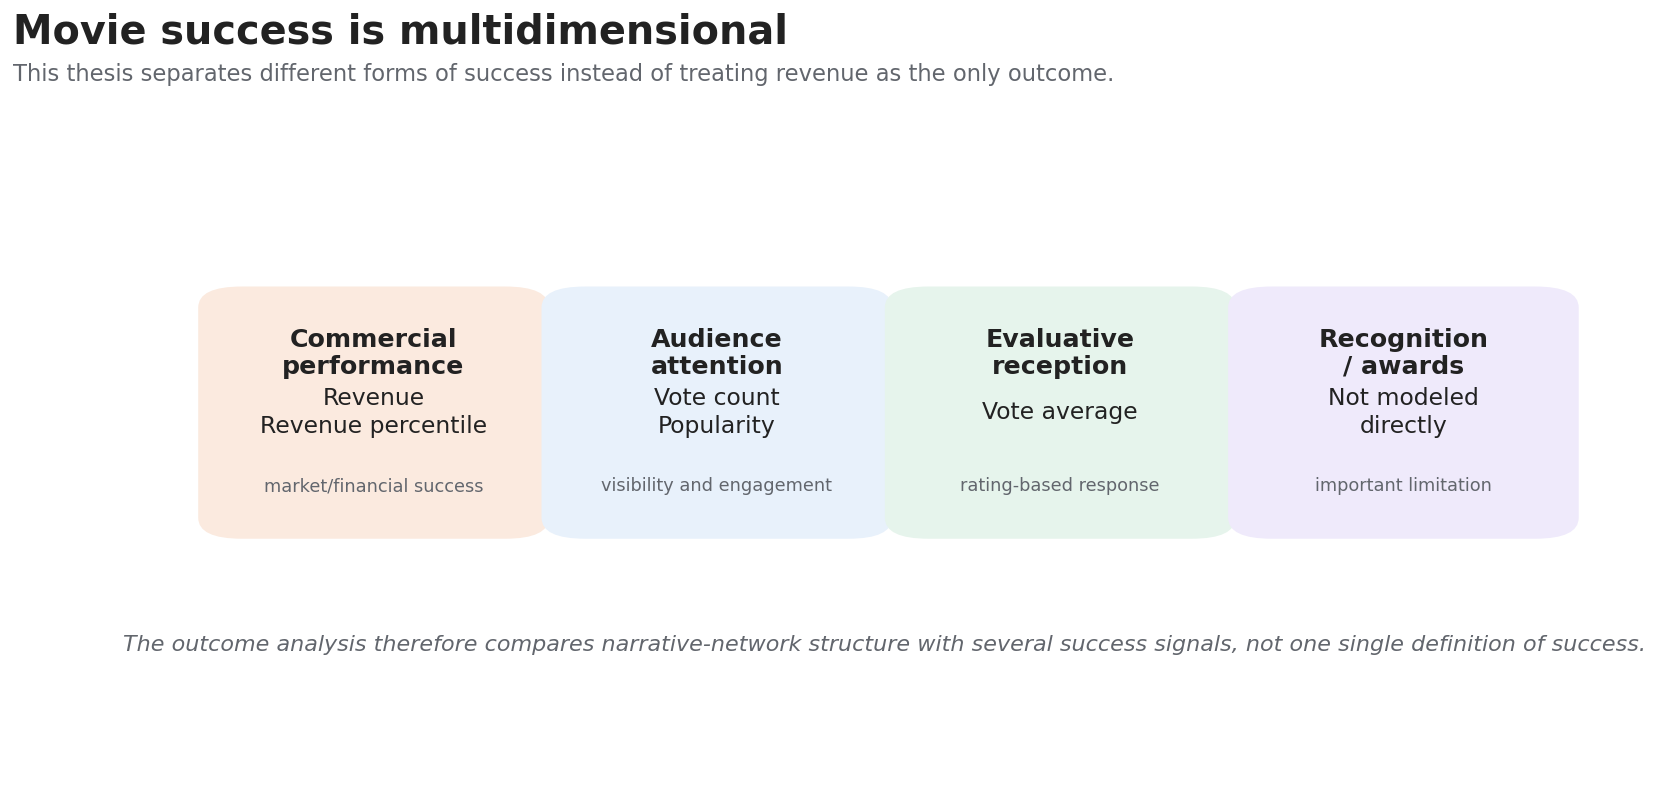

In [5]:

fig, ax = plt.subplots(figsize=(14.5, 7.0))
ax.axis("off")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

title_block(
    fig,
    "Movie success is multidimensional",
    "This thesis separates different forms of success instead of treating revenue as the only outcome."
)

cards = [
    (0.05, 0.38, 0.20, 0.32, COL["light_orange"], "Commercial\nperformance", "Revenue\nRevenue percentile", "market/financial success"),
    (0.285, 0.38, 0.20, 0.32, COL["light_blue"], "Audience\nattention", "Vote count\nPopularity", "visibility and engagement"),
    (0.52, 0.38, 0.20, 0.32, COL["light_green"], "Evaluative\nreception", "Vote average", "rating-based response"),
    (0.755, 0.38, 0.20, 0.32, COL["light_purple"], "Recognition\n/ awards", "Not modeled\ndirectly", "important limitation"),
]

for x, y, w, h, bg, title, variables, note in cards:
    ax.add_patch(FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.020,rounding_size=0.030",
        facecolor=bg,
        edgecolor="none"
    ))
    ax.text(x + w/2, y + h - 0.075, title, ha="center", va="center", fontsize=14, fontweight="bold", linespacing=1.15)
    ax.text(x + w/2, y + h/2, variables, ha="center", va="center", fontsize=13, linespacing=1.30)
    ax.text(x + w/2, y + 0.055, note, ha="center", va="center", fontsize=9.8, color=COL["muted"])

ax.text(
    0.5, 0.20,
    "The outcome analysis therefore compares narrative-network structure with several success signals, not one single definition of success.",
    ha="center",
    fontsize=12.3,
    color=COL["muted"],
    style="italic"
)

save_fig(fig, "01_success_dimensions_framework.png")
plt.show()


## 5. Figure 2 — Measurement table

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/07_success_dimensions/tables/02_success_variables_measurement_table.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/07_success_dimensions/figures/02_success_variables_measurement_table.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/07_success_dimensions/figures/02_success_variables_measurement_table.svg


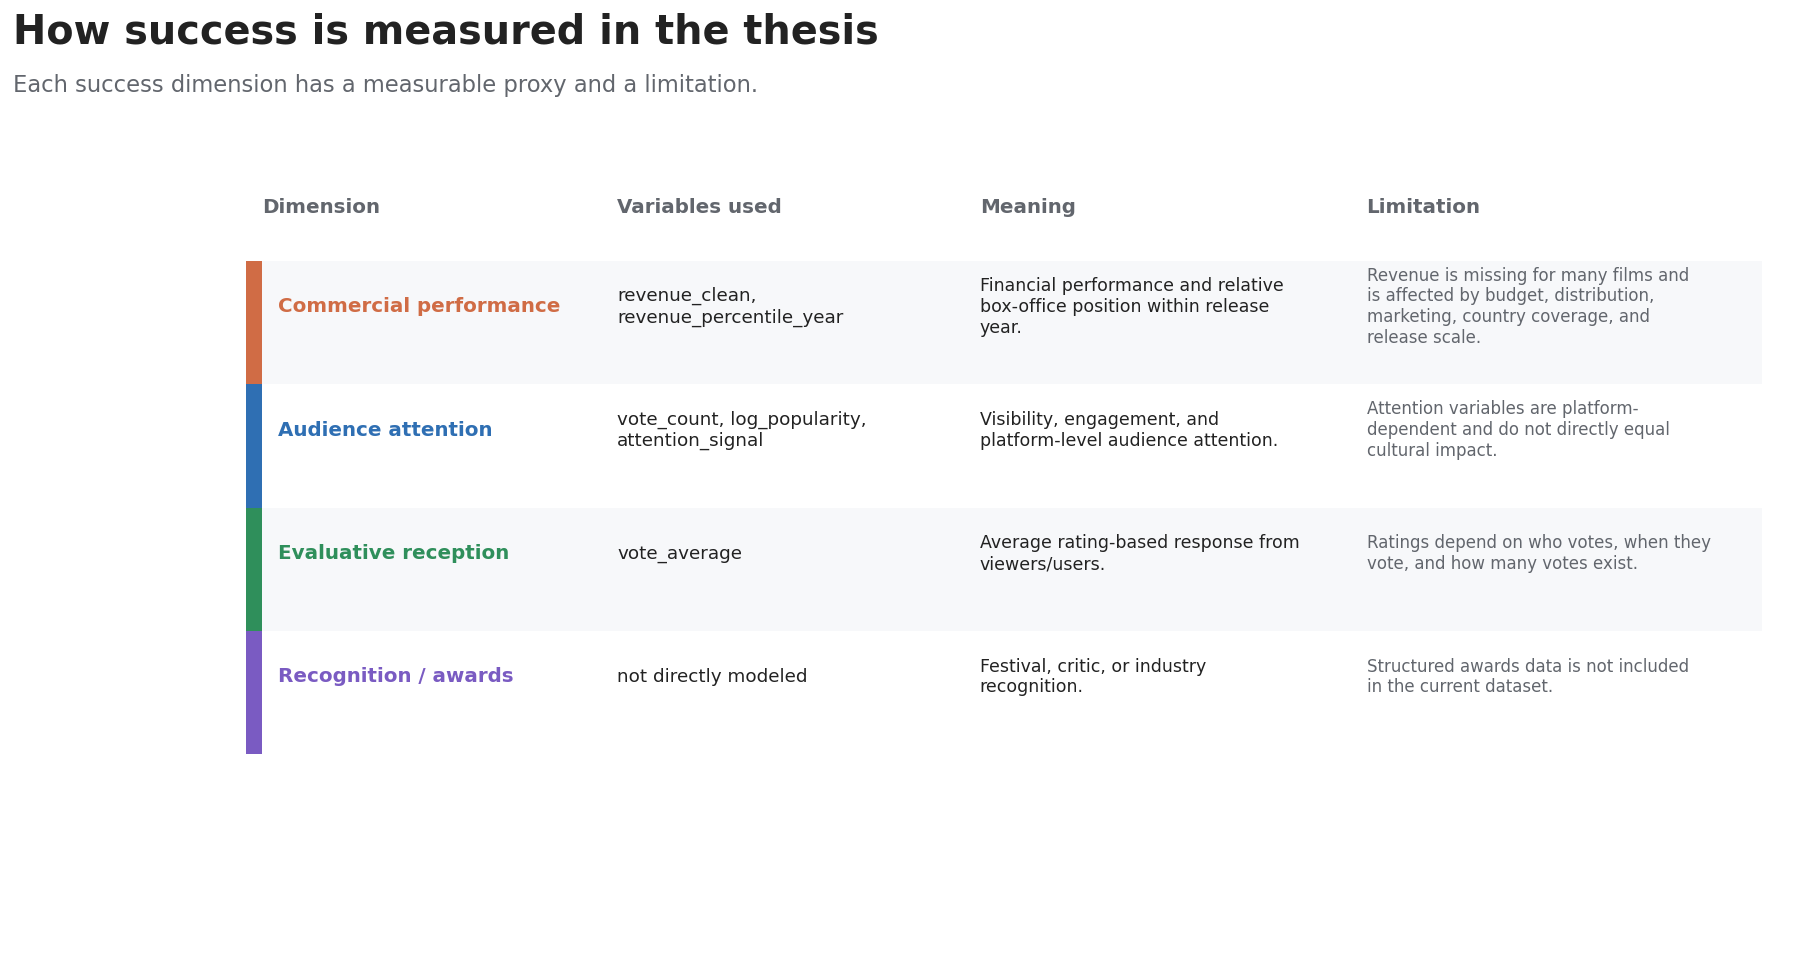

In [6]:

measurement_rows = [
    {
        "dimension": "Commercial performance",
        "available_variable": ", ".join([x for x in [revenue_col, revenue_percentile_col] if x]) or "not available",
        "thesis_meaning": "Financial performance and relative box-office position within release year.",
        "limitation": "Revenue is missing for many films and is affected by budget, distribution, marketing, country coverage, and release scale.",
        "color": COL["orange"],
    },
    {
        "dimension": "Audience attention",
        "available_variable": ", ".join([x for x in [vote_count_col, popularity_col, "attention_signal" if "attention_signal" in df.columns else None] if x]) or "not available",
        "thesis_meaning": "Visibility, engagement, and platform-level audience attention.",
        "limitation": "Attention variables are platform-dependent and do not directly equal cultural impact.",
        "color": COL["blue"],
    },
    {
        "dimension": "Evaluative reception",
        "available_variable": vote_average_col or "not available",
        "thesis_meaning": "Average rating-based response from viewers/users.",
        "limitation": "Ratings depend on who votes, when they vote, and how many votes exist.",
        "color": COL["green"],
    },
    {
        "dimension": "Recognition / awards",
        "available_variable": "not directly modeled",
        "thesis_meaning": "Festival, critic, or industry recognition.",
        "limitation": "Structured awards data is not included in the current dataset.",
        "color": COL["purple"],
    },
]

measurement = pd.DataFrame(measurement_rows)
save_table(measurement.drop(columns=["color"]), "02_success_variables_measurement_table.csv")

fig, ax = plt.subplots(figsize=(16, 8.5))
ax.axis("off")
title_block(
    fig,
    "How success is measured in the thesis",
    "Each success dimension has a measurable proxy and a limitation.",
    x=0.04,
    y=0.965
)

start_y = 0.80
row_h = 0.145
headers = ["Dimension", "Variables used", "Meaning", "Limitation"]
xs = [0.045, 0.265, 0.49, 0.73]

for x0, h in zip(xs, headers):
    ax.text(x0, start_y + 0.075, h, transform=ax.transAxes, fontsize=11, fontweight="bold", color=COL["muted"])

for i, r in measurement.iterrows():
    y = start_y - i * row_h
    bg = COL["panel"] if i % 2 == 0 else "white"
    ax.add_patch(patches.Rectangle((0.035, y - row_h + 0.018), 0.94, row_h, transform=ax.transAxes, facecolor=bg, edgecolor="none"))
    ax.add_patch(patches.Rectangle((0.035, y - row_h + 0.018), 0.010, row_h, transform=ax.transAxes, facecolor=r["color"], edgecolor="none"))

    ax.text(0.055, y - 0.035, wrap_text(r["dimension"], 22), transform=ax.transAxes, fontsize=11.0, fontweight="bold", color=r["color"], va="center")
    ax.text(0.265, y - 0.035, wrap_text(r["available_variable"], 27), transform=ax.transAxes, fontsize=10.2, va="center")
    ax.text(0.49, y - 0.035, wrap_text(r["thesis_meaning"], 34), transform=ax.transAxes, fontsize=9.6, color=COL["ink"], va="center")
    ax.text(0.73, y - 0.035, wrap_text(r["limitation"], 39), transform=ax.transAxes, fontsize=9.2, color=COL["muted"], va="center")

save_fig(fig, "02_success_variables_measurement_table.png")
plt.show()


## 6. Figure 3 — Outcome availability cards

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/07_success_dimensions/tables/03_outcome_availability_cards_table.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/07_success_dimensions/figures/03_outcome_availability_cards.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/07_success_dimensions/figures/03_outcome_availability_cards.svg


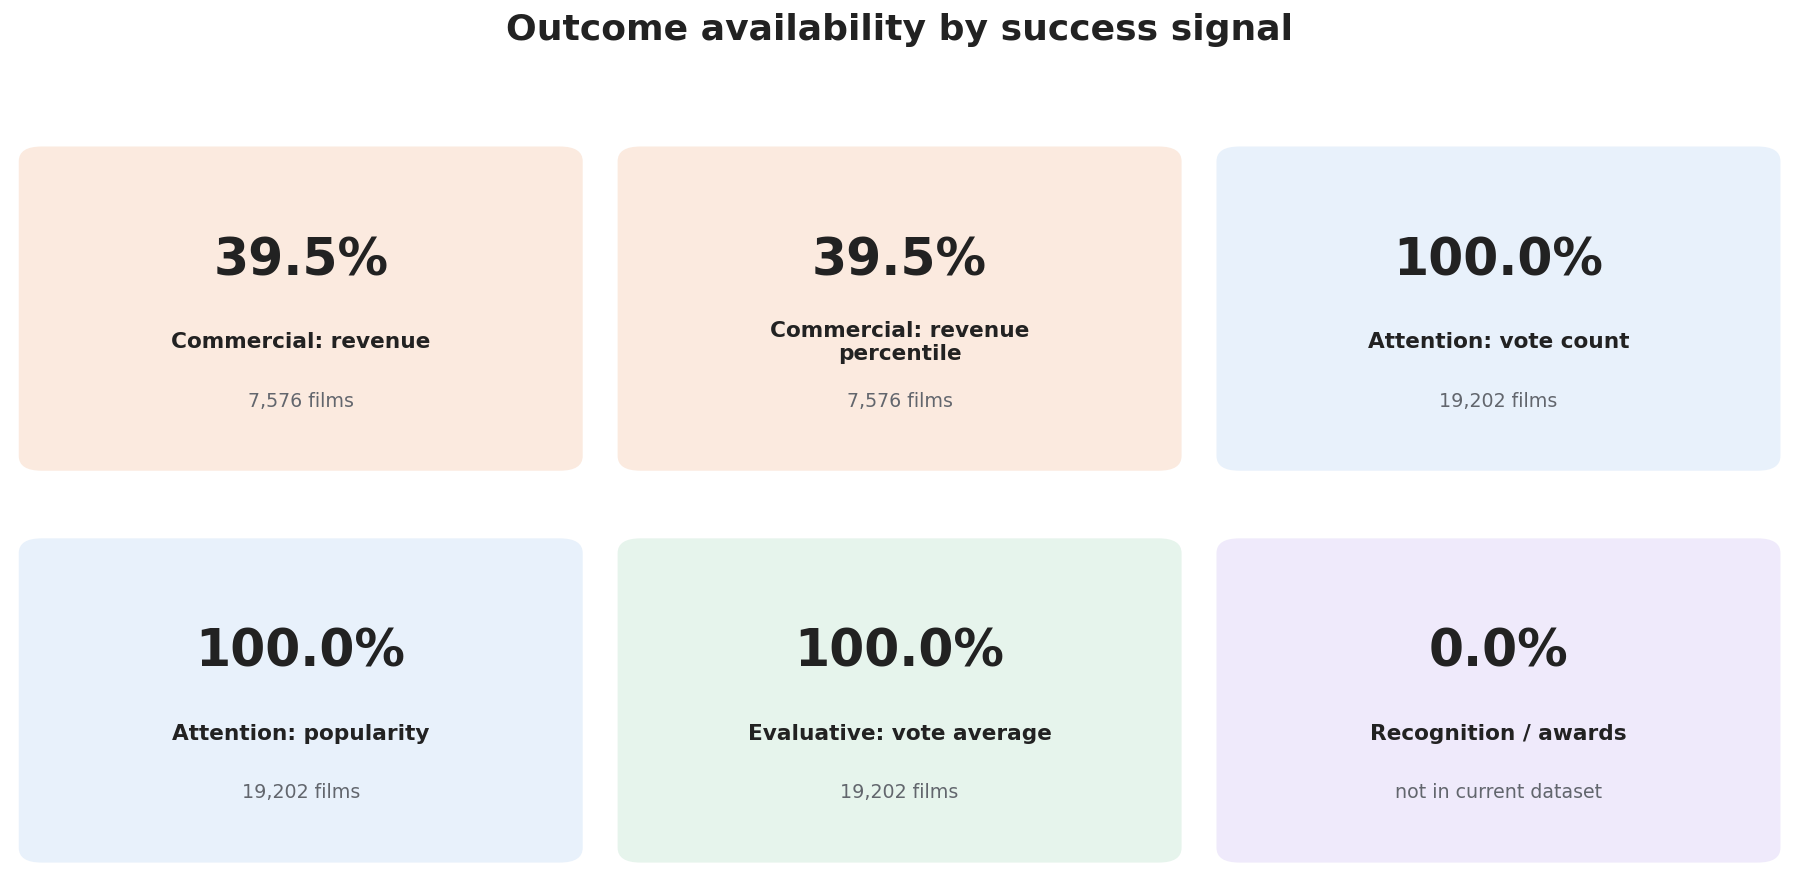

In [7]:

availability_items = []

candidate_vars = [
    ("Commercial: revenue", revenue_col, COL["light_orange"]),
    ("Commercial: revenue percentile", revenue_percentile_col, COL["light_orange"]),
    ("Attention: vote count", vote_count_col, COL["light_blue"]),
    ("Attention: popularity", popularity_col, COL["light_blue"]),
    ("Evaluative: vote average", vote_average_col, COL["light_green"]),
    ("Recognition / awards", None, COL["light_purple"]),
]

for label, col, bg in candidate_vars:
    if col is None:
        available_n = 0
        available_pct = 0.0
        note = "not in current dataset"
    else:
        available_n = int(df[col].notna().sum())
        available_pct = df[col].notna().mean() * 100
        note = f"{available_n:,} films"
    availability_items.append((label, available_pct, note, bg))

availability_df = pd.DataFrame(availability_items, columns=["success_signal", "available_pct", "note", "bg"])
save_table(availability_df.drop(columns=["bg"]), "03_outcome_availability_cards_table.csv")

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.ravel()

for ax, (label, pct, note, bg) in zip(axes, availability_items):
    ax.axis("off")
    rect = FancyBboxPatch(
        (0.04, 0.08), 0.92, 0.82,
        boxstyle="round,pad=0.03,rounding_size=0.04",
        facecolor=bg,
        edgecolor="none"
    )
    ax.add_patch(rect)
    ax.text(0.5, 0.62, f"{pct:.1f}%", ha="center", va="center", fontsize=28, fontweight="bold")
    ax.text(0.5, 0.40, wrap_text(label, 24), ha="center", va="center", fontsize=12.0, fontweight="bold")
    ax.text(0.5, 0.24, note, ha="center", va="center", fontsize=10.5, color=COL["muted"])

fig.suptitle("Outcome availability by success signal", fontsize=20, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])
save_fig(fig, "03_outcome_availability_cards.png")
plt.show()


## 7. Figure 4 — Revenue distribution

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/07_success_dimensions/tables/04_revenue_distribution_summary.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/07_success_dimensions/figures/04_revenue_distribution.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/07_success_dimensions/figures/04_revenue_distribution.svg


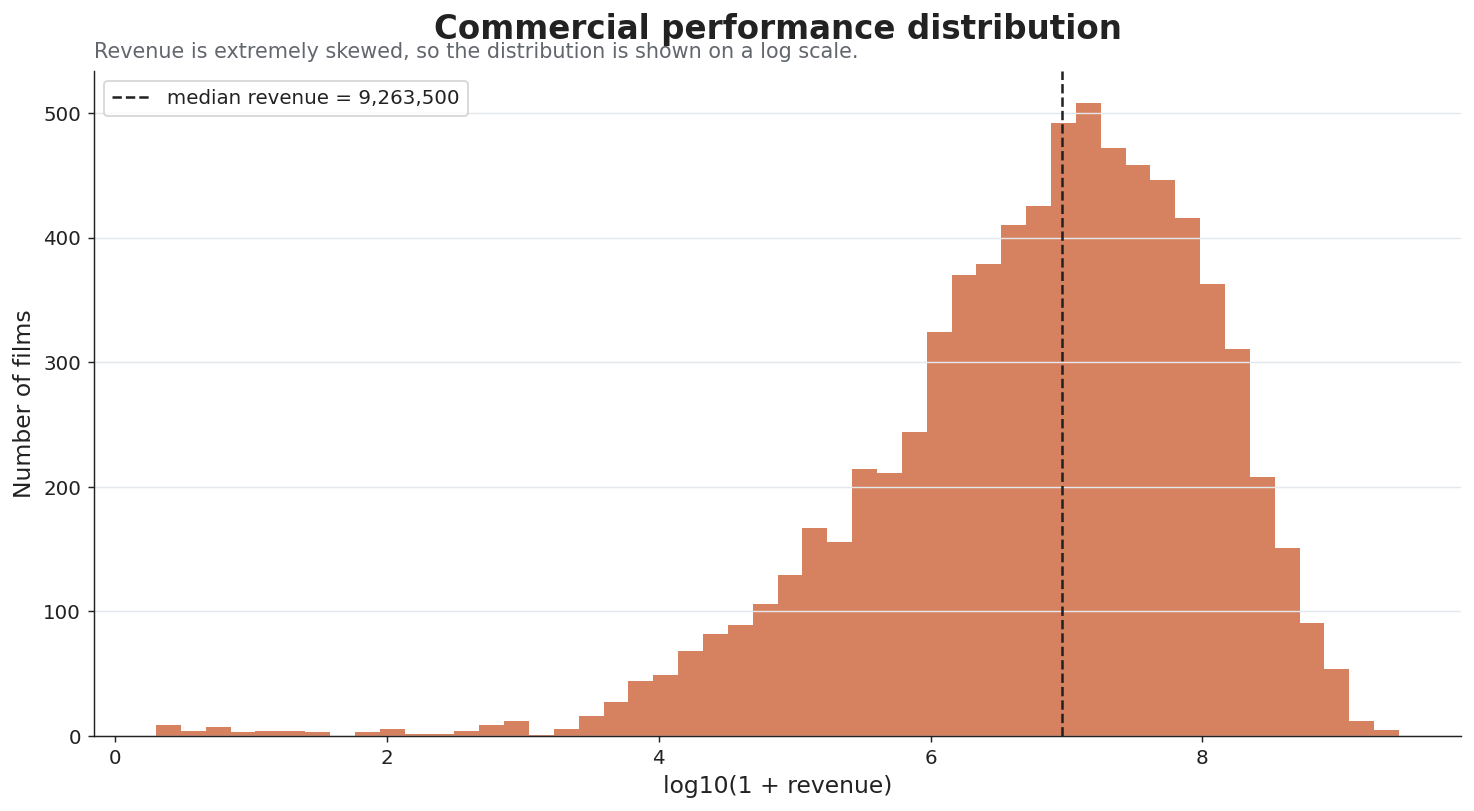

In [8]:

if revenue_col:
    temp = df.dropna(subset=[revenue_col]).copy()
    temp = temp[temp[revenue_col] > 0].copy()
    if len(temp):
        temp["log_revenue_plot"] = np.log10(temp[revenue_col] + 1)
        summary = pd.DataFrame({
            "metric": ["n", "median", "mean", "p75", "p90", "max"],
            "value": [len(temp), temp[revenue_col].median(), temp[revenue_col].mean(), temp[revenue_col].quantile(.75), temp[revenue_col].quantile(.90), temp[revenue_col].max()]
        })
        save_table(summary, "04_revenue_distribution_summary.csv")

        fig, ax = plt.subplots(figsize=(11.5, 6.4))
        ax.hist(temp["log_revenue_plot"], bins=50, color=COL["orange"], alpha=0.86)
        ax.axvline(np.log10(temp[revenue_col].median() + 1), color=COL["ink"], ls="--", lw=1.4, label=f"median revenue = {temp[revenue_col].median():,.0f}")

        ax.set_title("Commercial performance distribution", pad=18)
        ax.text(
            0, 1.02,
            "Revenue is extremely skewed, so the distribution is shown on a log scale.",
            transform=ax.transAxes,
            fontsize=11.5,
            color=COL["muted"]
        )
        ax.set_xlabel("log10(1 + revenue)")
        ax.set_ylabel("Number of films")
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", color=COL["grid"])
        ax.legend()

        plt.tight_layout()
        save_fig(fig, "04_revenue_distribution.png")
        plt.show()
    else:
        print("No positive revenue values.")
else:
    print("No revenue column found.")


## 8. Figure 5 — Vote-average distribution

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/07_success_dimensions/tables/05_vote_average_distribution_summary.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/07_success_dimensions/figures/05_vote_average_distribution.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/07_success_dimensions/figures/05_vote_average_distribution.svg


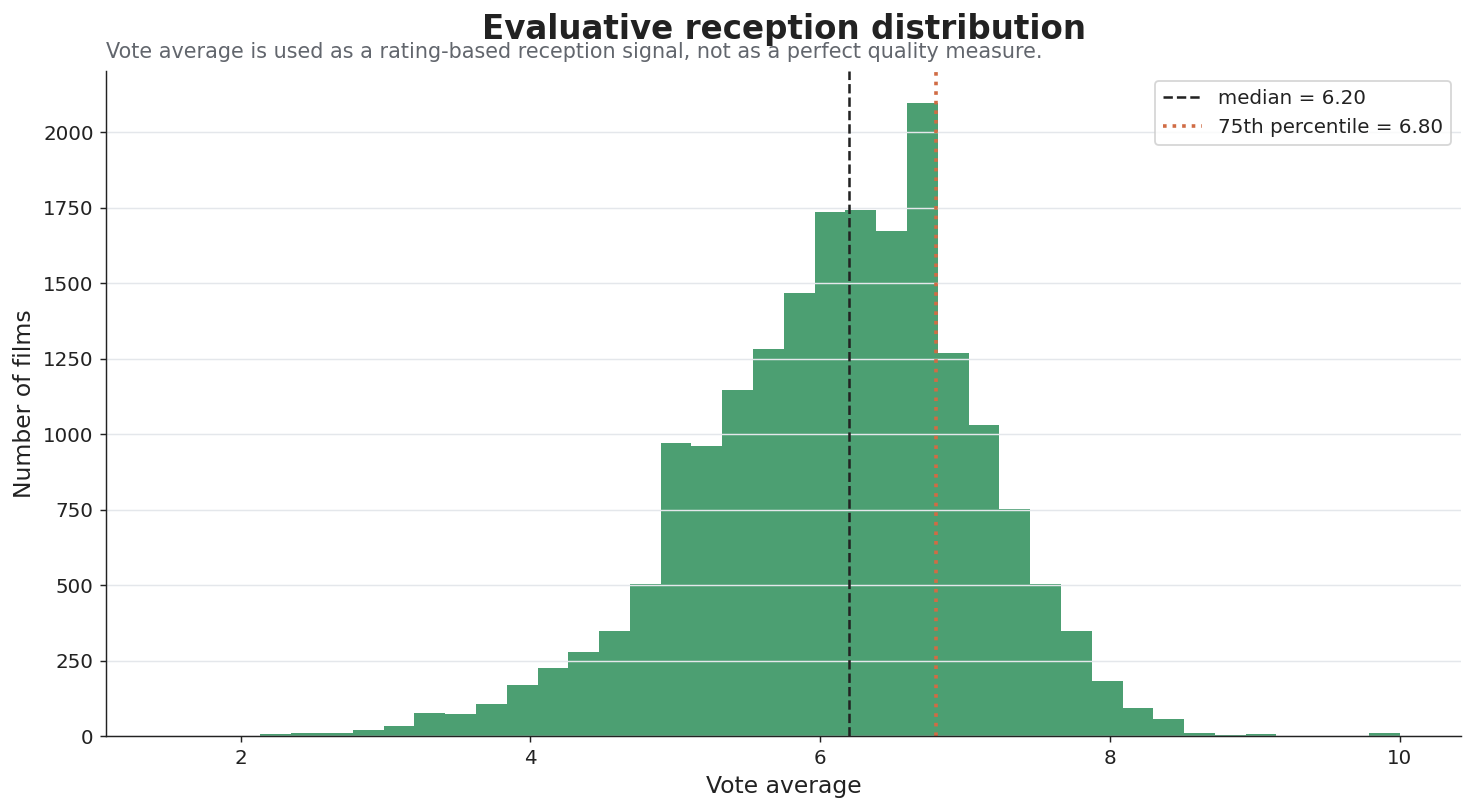

In [9]:

if vote_average_col:
    temp = df.dropna(subset=[vote_average_col]).copy()
    summary = pd.DataFrame({
        "metric": ["n", "median", "mean", "p25", "p75", "p90"],
        "value": [len(temp), temp[vote_average_col].median(), temp[vote_average_col].mean(), temp[vote_average_col].quantile(.25), temp[vote_average_col].quantile(.75), temp[vote_average_col].quantile(.90)]
    })
    save_table(summary, "05_vote_average_distribution_summary.csv")

    fig, ax = plt.subplots(figsize=(11.5, 6.4))
    ax.hist(temp[vote_average_col], bins=40, color=COL["green"], alpha=0.86)
    ax.axvline(temp[vote_average_col].median(), color=COL["ink"], ls="--", lw=1.4, label=f"median = {temp[vote_average_col].median():.2f}")
    ax.axvline(temp[vote_average_col].quantile(.75), color=COL["orange"], ls=":", lw=2.0, label=f"75th percentile = {temp[vote_average_col].quantile(.75):.2f}")

    ax.set_title("Evaluative reception distribution", pad=18)
    ax.text(
        0, 1.02,
        "Vote average is used as a rating-based reception signal, not as a perfect quality measure.",
        transform=ax.transAxes,
        fontsize=11.5,
        color=COL["muted"]
    )
    ax.set_xlabel("Vote average")
    ax.set_ylabel("Number of films")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color=COL["grid"])
    ax.legend()

    plt.tight_layout()
    save_fig(fig, "05_vote_average_distribution.png")
    plt.show()
else:
    print("No vote average column found.")


## 9. Figure 6 — Attention distribution

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/07_success_dimensions/tables/06_attention_distribution_summary.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/07_success_dimensions/figures/06_attention_distribution.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/07_success_dimensions/figures/06_attention_distribution.svg


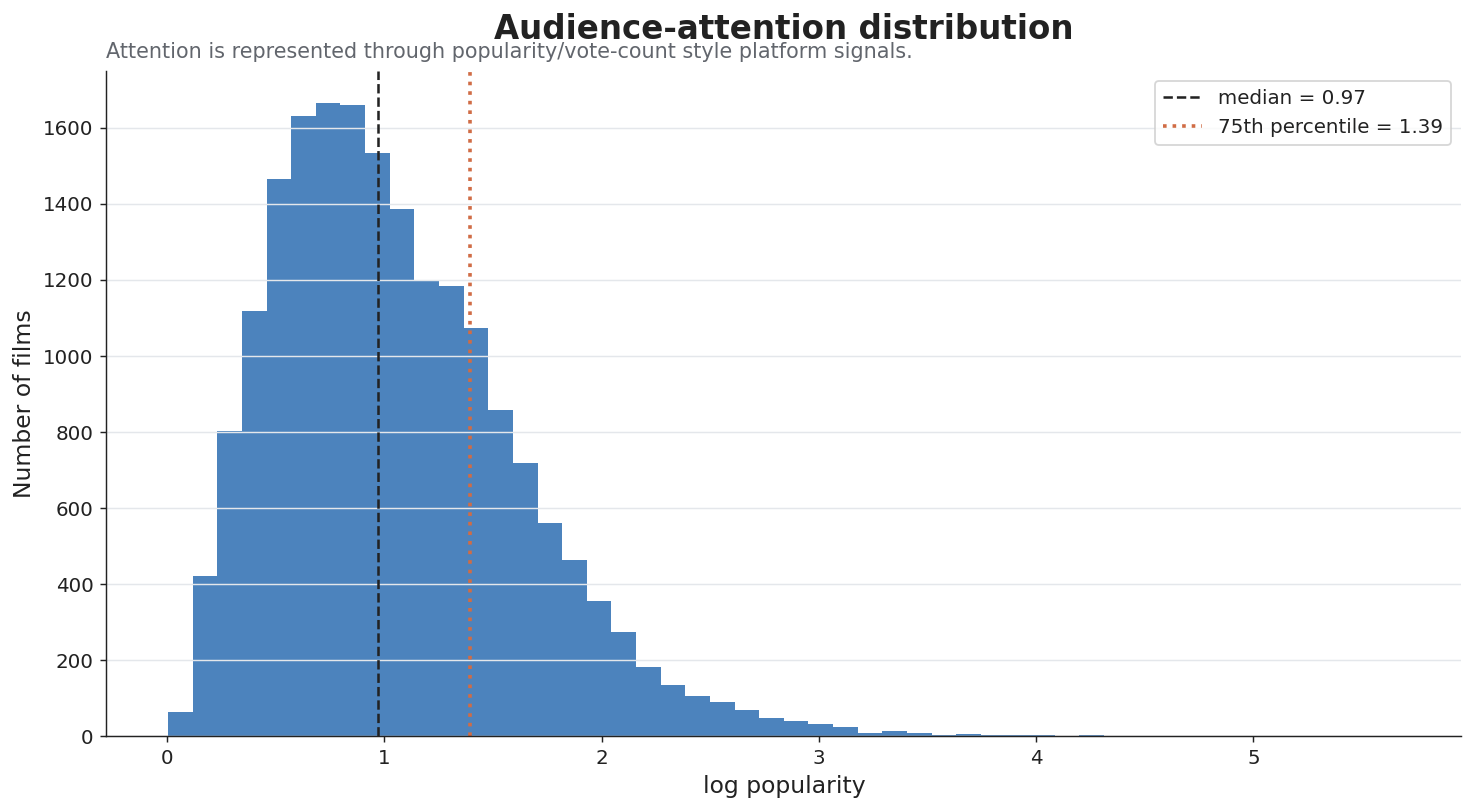

In [10]:

if "attention_signal" in df.columns:
    temp = df.dropna(subset=["attention_signal"]).copy()
    summary = pd.DataFrame({
        "metric": ["n", "median", "mean", "p75", "p90", "max"],
        "value": [len(temp), temp["attention_signal"].median(), temp["attention_signal"].mean(), temp["attention_signal"].quantile(.75), temp["attention_signal"].quantile(.90), temp["attention_signal"].max()]
    })
    save_table(summary, "06_attention_distribution_summary.csv")

    fig, ax = plt.subplots(figsize=(11.5, 6.4))
    ax.hist(temp["attention_signal"], bins=50, color=COL["blue"], alpha=0.86)
    ax.axvline(temp["attention_signal"].median(), color=COL["ink"], ls="--", lw=1.4, label=f"median = {temp['attention_signal'].median():.2f}")
    ax.axvline(temp["attention_signal"].quantile(.75), color=COL["orange"], ls=":", lw=2.0, label=f"75th percentile = {temp['attention_signal'].quantile(.75):.2f}")

    ax.set_title("Audience-attention distribution", pad=18)
    ax.text(
        0, 1.02,
        "Attention is represented through popularity/vote-count style platform signals.",
        transform=ax.transAxes,
        fontsize=11.5,
        color=COL["muted"]
    )
    ax.set_xlabel(attention_label or "attention signal")
    ax.set_ylabel("Number of films")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color=COL["grid"])
    ax.legend()

    plt.tight_layout()
    save_fig(fig, "06_attention_distribution.png")
    plt.show()
else:
    print("No attention signal available.")


## 10. Figure 7 — Success quadrant concept

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/07_success_dimensions/figures/07_success_quadrant_concept.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/07_success_dimensions/figures/07_success_quadrant_concept.svg


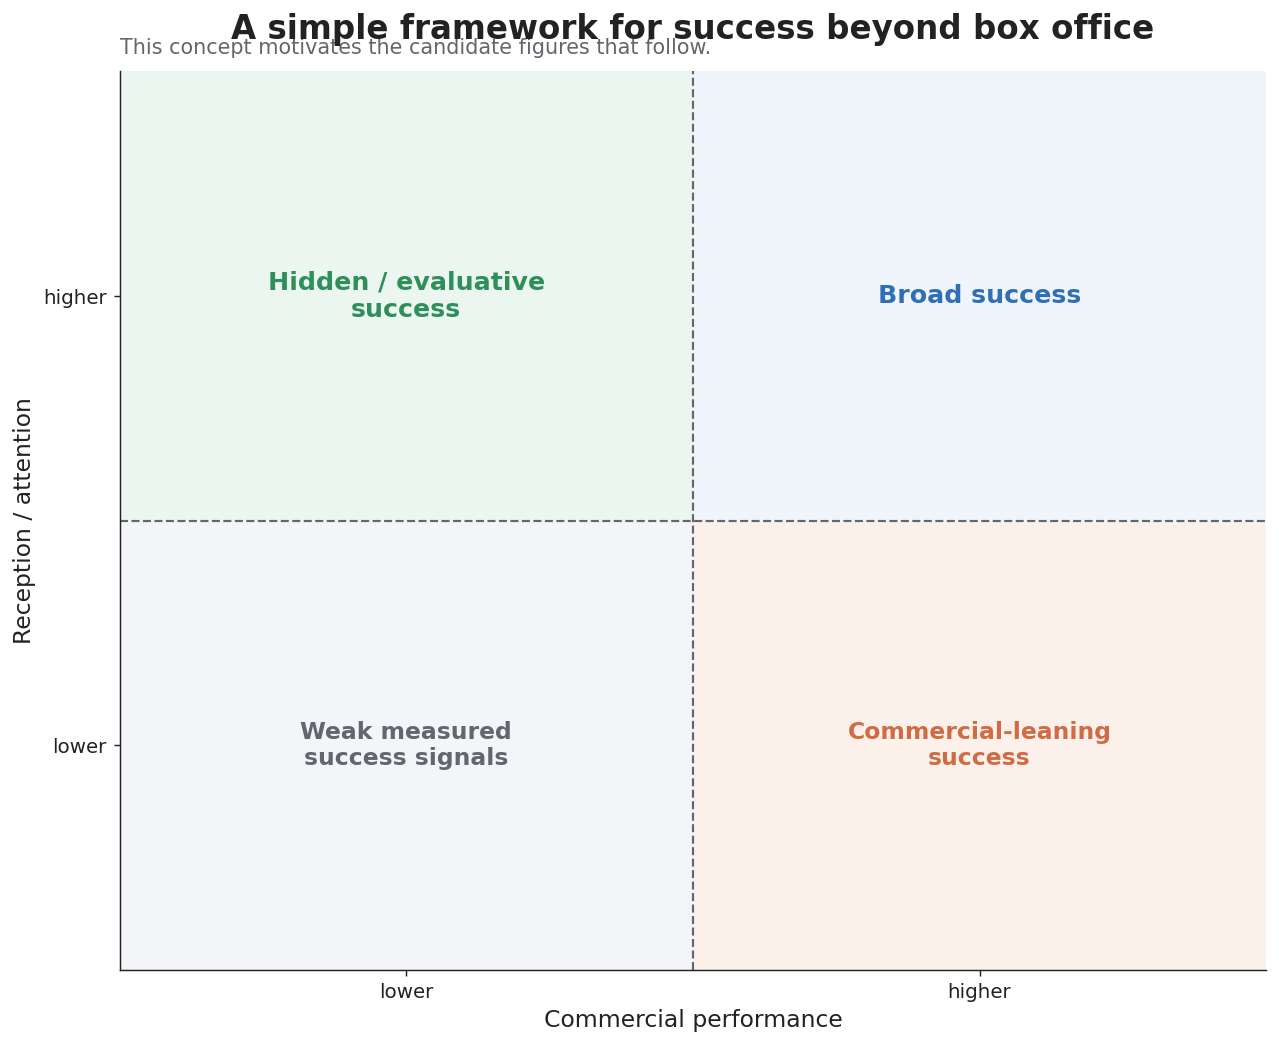

In [11]:

fig, ax = plt.subplots(figsize=(10, 8.2))

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axvline(0.5, color=COL["muted"], ls="--", lw=1.2)
ax.axhline(0.5, color=COL["muted"], ls="--", lw=1.2)

# Quadrant backgrounds.
ax.add_patch(patches.Rectangle((0.00, 0.50), 0.50, 0.50, facecolor=COL["light_green"], alpha=0.75, zorder=0))
ax.add_patch(patches.Rectangle((0.50, 0.50), 0.50, 0.50, facecolor=COL["light_blue"], alpha=0.65, zorder=0))
ax.add_patch(patches.Rectangle((0.00, 0.00), 0.50, 0.50, facecolor=COL["light_gray"], alpha=0.85, zorder=0))
ax.add_patch(patches.Rectangle((0.50, 0.00), 0.50, 0.50, facecolor=COL["light_orange"], alpha=0.65, zorder=0))

ax.text(0.25, 0.75, "Hidden / evaluative\nsuccess", ha="center", va="center", fontsize=14, fontweight="bold", color=COL["green"])
ax.text(0.75, 0.75, "Broad success", ha="center", va="center", fontsize=14, fontweight="bold", color=COL["blue"])
ax.text(0.25, 0.25, "Weak measured\nsuccess signals", ha="center", va="center", fontsize=13, fontweight="bold", color=COL["muted"])
ax.text(0.75, 0.25, "Commercial-leaning\nsuccess", ha="center", va="center", fontsize=13, fontweight="bold", color=COL["orange"])

ax.set_xlabel("Commercial performance")
ax.set_ylabel("Reception / attention")
ax.set_xticks([0.25, 0.75])
ax.set_xticklabels(["lower", "higher"])
ax.set_yticks([0.25, 0.75])
ax.set_yticklabels(["lower", "higher"])

ax.set_title("A simple framework for success beyond box office", pad=18)
ax.text(
    0, 1.02,
    "This concept motivates the candidate figures that follow.",
    transform=ax.transAxes,
    fontsize=11.5,
    color=COL["muted"]
)
ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
save_fig(fig, "07_success_quadrant_concept.png")
plt.show()


## 11. Figure 8 — Hidden/evaluative success candidates

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/07_success_dimensions/tables/08_hidden_evaluative_success_candidates.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/07_success_dimensions/figures/08_hidden_evaluative_success_candidates.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/07_success_dimensions/figures/08_hidden_evaluative_success_candidates.svg


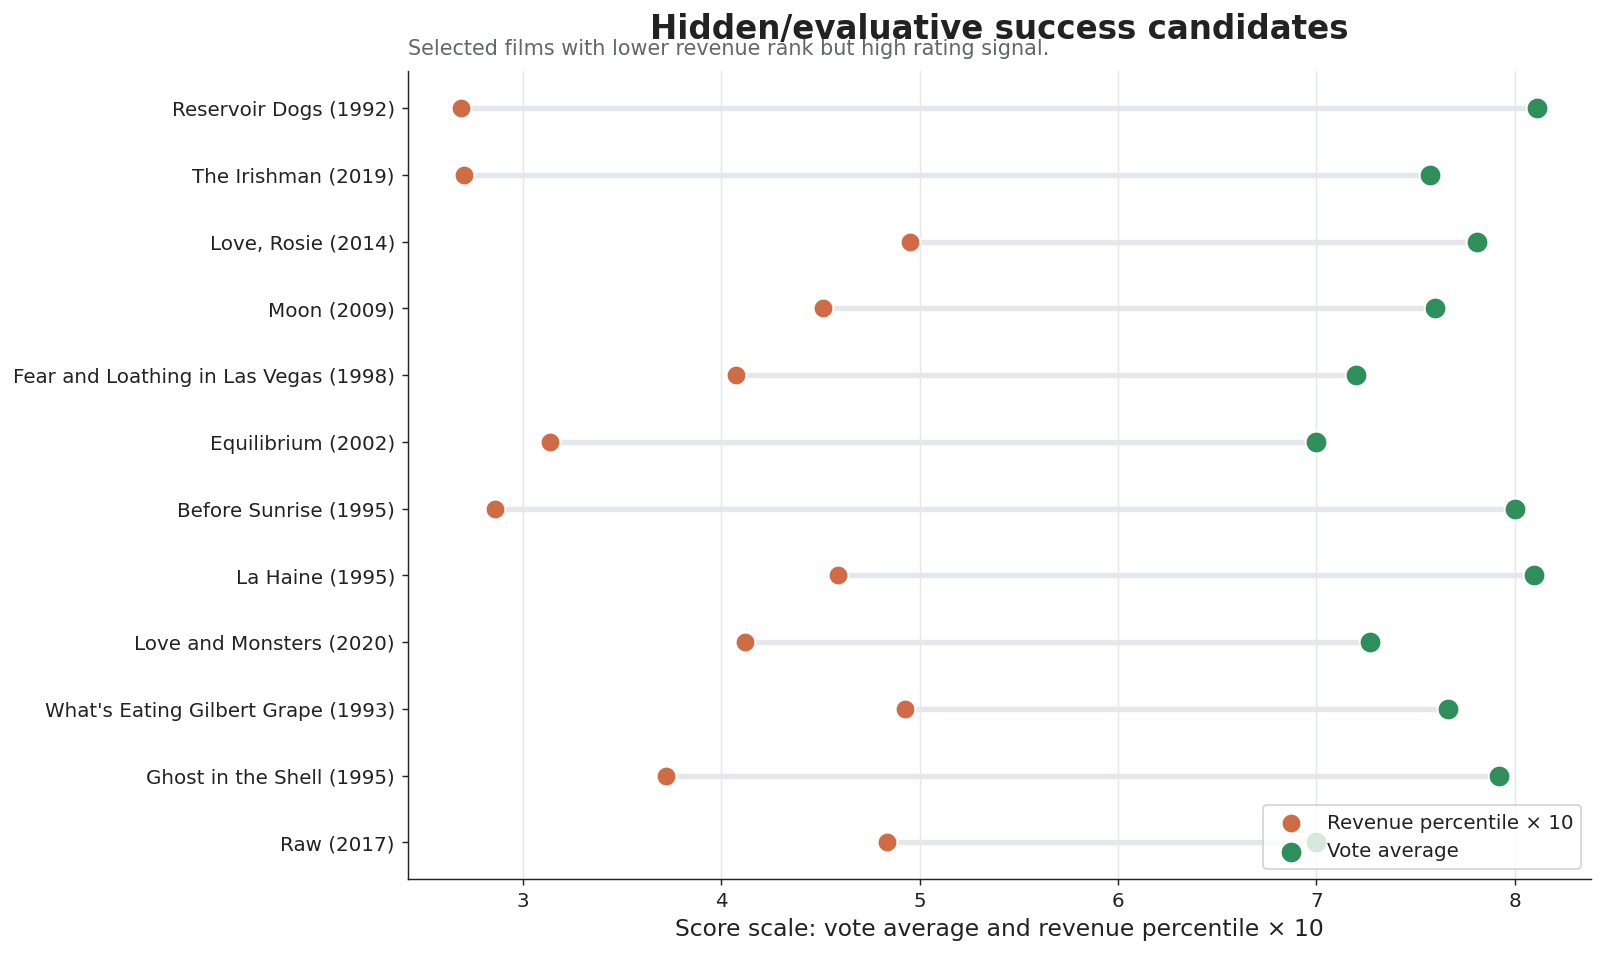

In [12]:

if revenue_percentile_col and vote_average_col:
    temp = df.dropna(subset=[revenue_percentile_col, vote_average_col]).copy()
    vote_threshold = temp[vote_average_col].quantile(.75)
    revenue_threshold = 0.50

    candidates = temp[
        (temp[revenue_percentile_col] <= revenue_threshold) &
        (temp[vote_average_col] >= vote_threshold)
    ].copy()

    # Prefer candidates with sufficient audience signal if vote_count exists.
    if vote_count_col and vote_count_col in candidates.columns:
        candidates = candidates.sort_values([vote_count_col, vote_average_col], ascending=False)
    else:
        candidates = candidates.sort_values(vote_average_col, ascending=False)

    candidates = candidates.head(12).copy()
    candidates["revenue_percentile_scaled_10"] = candidates[revenue_percentile_col] * 10

    save_table(candidates, "08_hidden_evaluative_success_candidates.csv")

    fig, ax = plt.subplots(figsize=(12.5, 7.5))
    y = np.arange(len(candidates))[::-1]
    labels = []
    for _, r in candidates.iterrows():
        title = clean_title(r.get(title_col, ""))
        year = r.get(year_col, "")
        try:
            if pd.notna(year):
                year = int(year)
        except Exception:
            pass
        labels.append(f"{title} ({year})" if year != "" else title)

    # Dumbbell: revenue percentile scaled vs vote average
    ax.scatter(candidates["revenue_percentile_scaled_10"], y, s=120, color=COL["orange"], edgecolor="white", linewidth=1.1, zorder=3, label="Revenue percentile × 10")
    ax.scatter(candidates[vote_average_col], y, s=145, color=COL["green"], edgecolor="white", linewidth=1.1, zorder=3, label="Vote average")

    for yi, (_, r) in zip(y, candidates.iterrows()):
        ax.plot([r["revenue_percentile_scaled_10"], r[vote_average_col]], [yi, yi], color=COL["grid"], lw=3.0, zorder=1)

    ax.set_yticks(y)
    ax.set_yticklabels([shorten(x, 42) for x in labels])
    ax.set_xlabel("Score scale: vote average and revenue percentile × 10")
    ax.set_title("Hidden/evaluative success candidates", pad=18)
    ax.text(
        0, 1.02,
        "Selected films with lower revenue rank but high rating signal.",
        transform=ax.transAxes,
        fontsize=11.5,
        color=COL["muted"]
    )
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color=COL["grid"])
    ax.legend(loc="lower right")

    plt.tight_layout()
    save_fig(fig, "08_hidden_evaluative_success_candidates.png")
    plt.show()
else:
    print("Need revenue percentile and vote average columns for hidden/evaluative candidates.")


## 12. Figure 9 — Attention success candidates

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/07_success_dimensions/tables/09_attention_success_candidates.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/07_success_dimensions/figures/09_attention_success_candidates.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/07_success_dimensions/figures/09_attention_success_candidates.svg


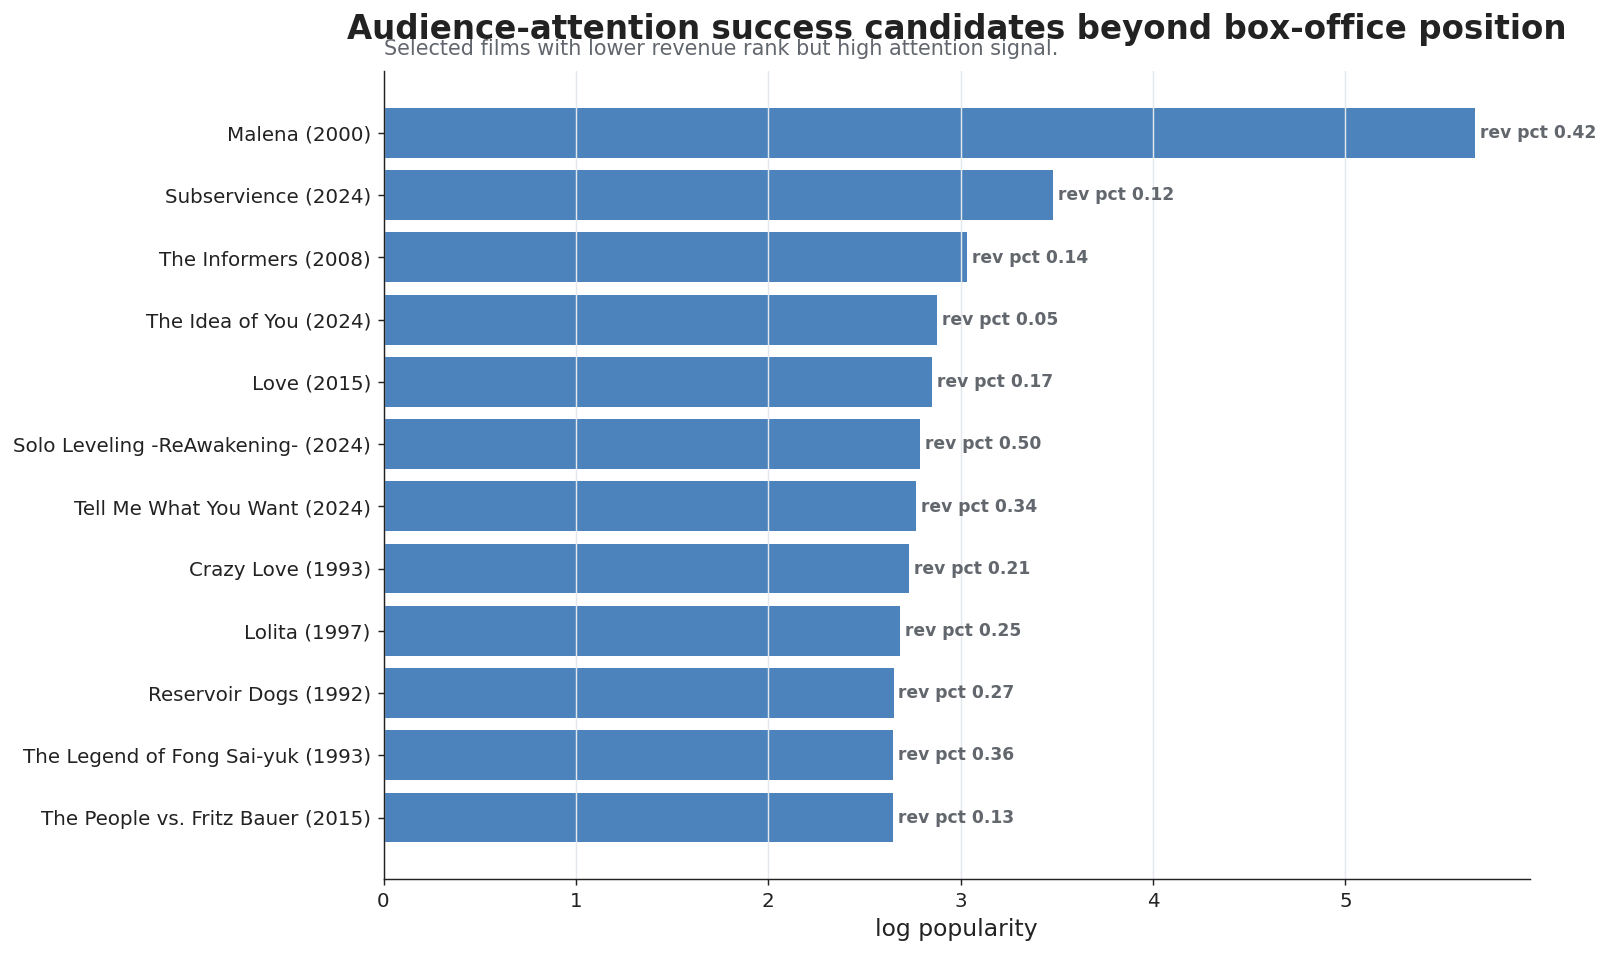

In [13]:

if revenue_percentile_col and "attention_signal" in df.columns:
    temp = df.dropna(subset=[revenue_percentile_col, "attention_signal"]).copy()
    attention_threshold = temp["attention_signal"].quantile(.75)
    revenue_threshold = 0.50

    candidates = temp[
        (temp[revenue_percentile_col] <= revenue_threshold) &
        (temp["attention_signal"] >= attention_threshold)
    ].copy()

    candidates = candidates.sort_values("attention_signal", ascending=False).head(12).copy()

    save_table(candidates, "09_attention_success_candidates.csv")

    fig, ax = plt.subplots(figsize=(12.5, 7.5))
    y = np.arange(len(candidates))[::-1]
    labels = []
    for _, r in candidates.iterrows():
        title = clean_title(r.get(title_col, ""))
        year = r.get(year_col, "")
        try:
            if pd.notna(year):
                year = int(year)
        except Exception:
            pass
        labels.append(f"{title} ({year})" if year != "" else title)

    ax.barh(y, candidates["attention_signal"], color=COL["blue"], alpha=0.86)

    for yi, (_, r) in zip(y, candidates.iterrows()):
        ax.text(
            r["attention_signal"] + 0.025,
            yi,
            f"rev pct {r[revenue_percentile_col]:.2f}",
            va="center",
            fontsize=9.5,
            color=COL["muted"],
            fontweight="bold"
        )

    ax.set_yticks(y)
    ax.set_yticklabels([shorten(x, 42) for x in labels])
    ax.set_xlabel(attention_label or "attention signal")
    ax.set_title("Audience-attention success candidates beyond box-office position", pad=18)
    ax.text(
        0, 1.02,
        "Selected films with lower revenue rank but high attention signal.",
        transform=ax.transAxes,
        fontsize=11.5,
        color=COL["muted"]
    )
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color=COL["grid"])

    plt.tight_layout()
    save_fig(fig, "09_attention_success_candidates.png")
    plt.show()
else:
    print("Need revenue percentile and attention signal for attention-success candidates.")


## 13. Figure 10 — Success dimensions summary

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/07_success_dimensions/figures/10_success_dimensions_summary.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/07_success_dimensions/figures/10_success_dimensions_summary.svg


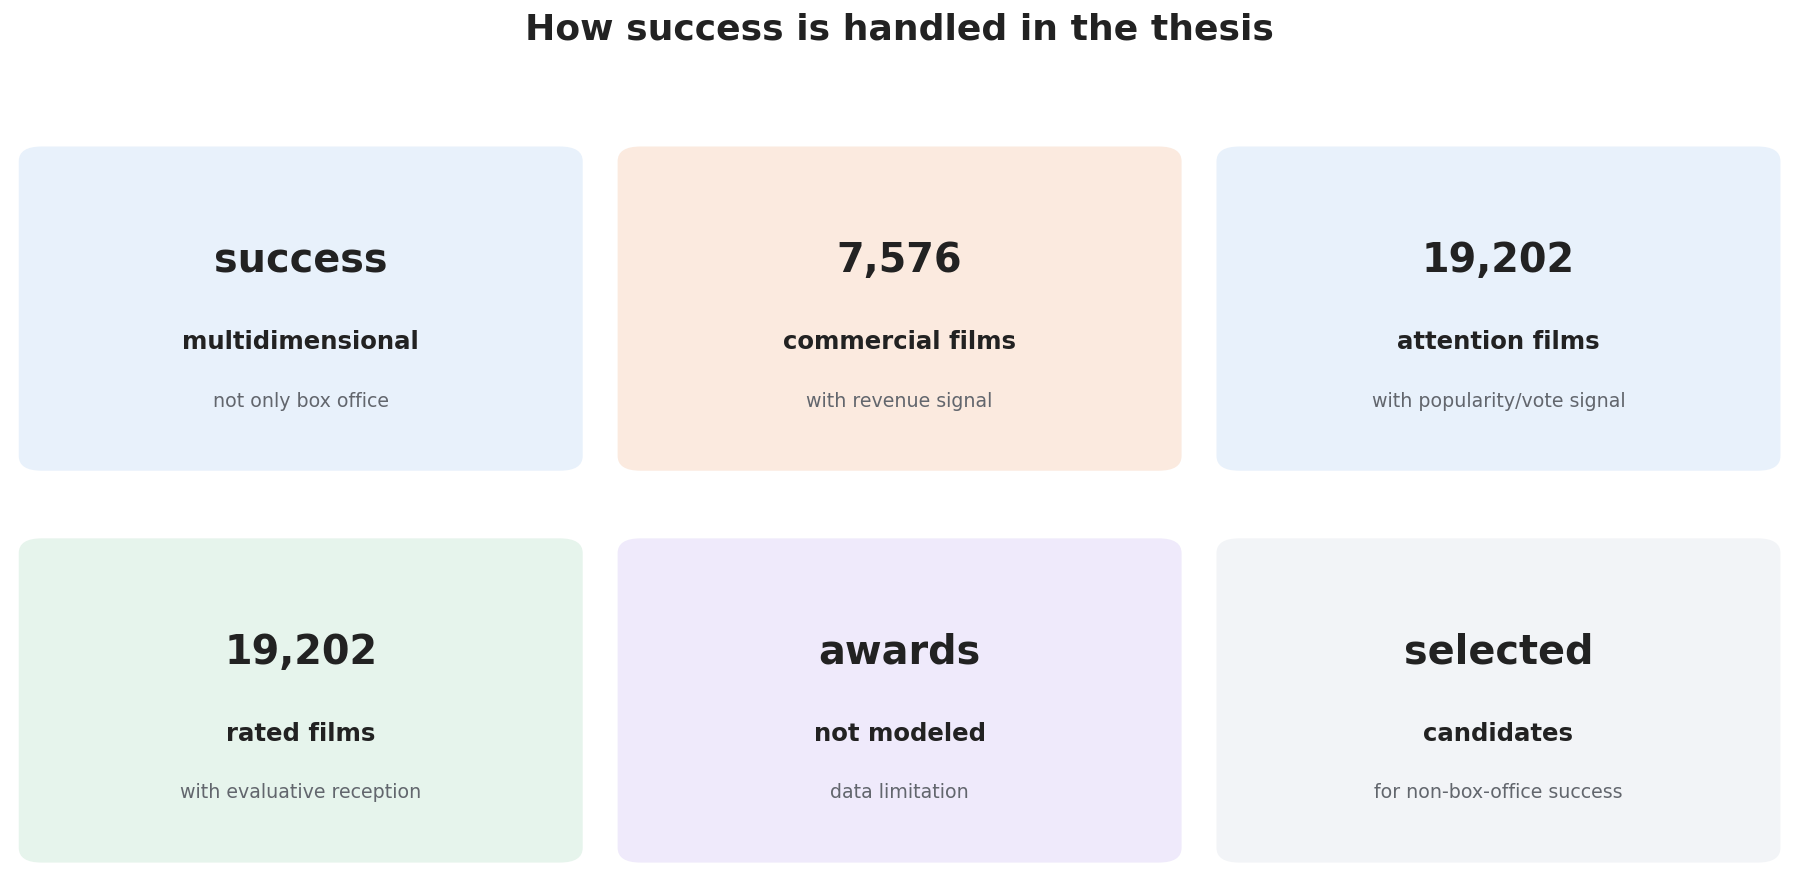

In [14]:

n_total = len(df)
n_revenue = int(df[revenue_col].notna().sum()) if revenue_col else 0
n_rating = int(df[vote_average_col].notna().sum()) if vote_average_col else 0
n_attention = int(df["attention_signal"].notna().sum()) if "attention_signal" in df.columns else 0

cards = [
    ("success", "multidimensional", "not only box office", COL["light_blue"]),
    (fmt_int(n_revenue), "commercial films", "with revenue signal", COL["light_orange"]),
    (fmt_int(n_attention), "attention films", "with popularity/vote signal", COL["light_blue"]),
    (fmt_int(n_rating), "rated films", "with evaluative reception", COL["light_green"]),
    ("awards", "not modeled", "data limitation", COL["light_purple"]),
    ("selected", "candidates", "for non-box-office success", COL["light_gray"]),
]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.ravel()

for ax, (value, title, subtitle, bg) in zip(axes, cards):
    ax.axis("off")
    rect = FancyBboxPatch(
        (0.04, 0.08), 0.92, 0.82,
        boxstyle="round,pad=0.03,rounding_size=0.04",
        facecolor=bg,
        edgecolor="none"
    )
    ax.add_patch(rect)
    ax.text(0.5, 0.62, value, ha="center", va="center", fontsize=22, fontweight="bold")
    ax.text(0.5, 0.40, title, ha="center", va="center", fontsize=13.5, fontweight="bold")
    ax.text(0.5, 0.24, wrap_text(subtitle, 28), ha="center", va="center", fontsize=10.5, color=COL["muted"])

fig.suptitle("How success is handled in the thesis", fontsize=20, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])
save_fig(fig, "10_success_dimensions_summary.png")
plt.show()


## 14. Export interpretation note

In [15]:

note = """
Brick 7 — Success dimensions interpretation note

This section should appear after the network-position sections and before the final outcome-association section.

Main message:
The thesis treats success as multidimensional. Commercial performance, audience attention, evaluative reception, and recognition are conceptually different. The available dataset supports direct analysis of revenue, popularity/vote-count style attention, and vote average. Awards and formal recognition are discussed as important but not directly modeled because structured awards data is not included.

Recommended main thesis figures:
1. 01_success_dimensions_framework.png
2. 02_success_variables_measurement_table.png
3. 03_outcome_availability_cards.png
4. 07_success_quadrant_concept.png
5. 08_hidden_evaluative_success_candidates.png
6. 09_attention_success_candidates.png

Recommended appendix/supporting figures:
1. 04_revenue_distribution.png
2. 05_vote_average_distribution.png
3. 06_attention_distribution.png
4. 10_success_dimensions_summary.png

Important wording:
Do not write that the thesis predicts movie success. The correct framing is that the thesis compares plot-network structure with different success signals and uses candidate figures to show why success cannot be reduced to box office alone.
""".strip()

write_text(note, "brick_07_interpretation_note.txt")
print(note)


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/07_success_dimensions/text/brick_07_interpretation_note.txt
Brick 7 — Success dimensions interpretation note

This section should appear after the network-position sections and before the final outcome-association section.

Main message:
The thesis treats success as multidimensional. Commercial performance, audience attention, evaluative reception, and recognition are conceptually different. The available dataset supports direct analysis of revenue, popularity/vote-count style attention, and vote average. Awards and formal recognition are discussed as important but not directly modeled because structured awards data is not included.

Recommended main thesis figures:
1. 01_success_dimensions_framework.png
2. 02_success_variables_measurement_table.png
3. 03_outcome_availability_cards.png
4. 07_success_quadrant_concept.png
5. 08_hidden_evaluative_success_candidates.png
6. 09_attention_success_candidates.png

Recommen

## 15. Output check

In [16]:

print("Figures:")
for p in sorted(FIG_DIR.glob("*.png")):
    print("-", p.name)

print("\nTables:")
for p in sorted(TABLE_DIR.glob("*.csv")):
    print("-", p.name)

print("\nText:")
for p in sorted(TEXT_DIR.glob("*.txt")):
    print("-", p.name)


Figures:
- 01_success_dimensions_framework.png
- 02_success_variables_measurement_table.png
- 03_outcome_availability_cards.png
- 04_revenue_distribution.png
- 05_vote_average_distribution.png
- 06_attention_distribution.png
- 07_success_quadrant_concept.png
- 08_hidden_evaluative_success_candidates.png
- 09_attention_success_candidates.png
- 10_success_dimensions_summary.png

Tables:
- 00_detected_success_columns.csv
- 00_success_dimensions_prepared_modeling_table.csv
- 02_success_variables_measurement_table.csv
- 03_outcome_availability_cards_table.csv
- 04_revenue_distribution_summary.csv
- 05_vote_average_distribution_summary.csv
- 06_attention_distribution_summary.csv
- 08_hidden_evaluative_success_candidates.csv
- 09_attention_success_candidates.csv

Text:
- brick_07_interpretation_note.txt
